In [44]:
# checking if path exists
from pathlib import Path 

root = Path("../data/raw/cifake")
print(root.exists())

True


In [45]:
# checking the numbers of images in the dataset as per the description
for split in ["train", "test"]:
    for cls in ["REAL", "FAKE"]:
        folder = root/split/cls
        n = len(list(folder.glob("*.jpg")))
        print(split, cls, n)

train REAL 50000
train FAKE 50000
test REAL 10000
test FAKE 10000


1006 (3).jpg JPEG (32, 32) RGB


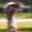

In [46]:
#checking the image name, format, size
from PIL import Image

path = next((root/"train"/"REAL").glob("*.jpg"))
im = Image.open(path)

print(path.name, im.format, im.size, im.mode)
im


In [47]:
#Checking if all the formats are correct 

from collections import Counter 

formats = Counter()

for split in ["train","test"]:
    for cls in ["REAL", "FAKE"]:
        for p in (root/split/cls).glob("*.jpg"):
            with Image.open(p) as im: 
                formats[(split, cls, im.format, im.size, im.mode)] += 1
print(formats)
                

Counter({('train', 'REAL', 'JPEG', (32, 32), 'RGB'): 50000, ('train', 'FAKE', 'JPEG', (32, 32), 'RGB'): 50000, ('test', 'REAL', 'JPEG', (32, 32), 'RGB'): 10000, ('test', 'FAKE', 'JPEG', (32, 32), 'RGB'): 10000})


In [48]:
# from audit.py checking if test/FAKE/0 (7).jpg and train/FAKE/3052 (7).jpg. are
# actually duplicate values contributing for data leakage. 

import hashlib
import numpy as np

def pixel_hash(path):
    arr = np.asarray(Image.open(path).convert("RGB"))
    return hashlib.md5(arr.tobytes()).hexdigest()

a = root / "test" / "FAKE" / "0 (7).jpg"
b = root / "train" / "FAKE" / "3052 (7).jpg"
c = next((root / "train" / "REAL").glob("*.jpg"))

print(pixel_hash(a) == pixel_hash(b))   # expecting True as the audit.py said they match)
print(pixel_hash(a) == pixel_hash(c))   
print(pixel_hash(a))                    # a 32-character fingerprint

ar= np.asarray(Image.open(a).convert("RGB"))
#print(ar)
print(ar.shape[0])


True
False
d7c02b9e30ba566c9e572bb9687a6b4d
32


In [49]:
train_hashes = {pixel_hash(p) for p in (root / "train").rglob("*.jpg")}
test_paths = list((root / "test").rglob("*.jpg"))
leaked = [p for p in test_paths if pixel_hash(p) in train_hashes]
print(len(leaked), "of", len(test_paths))
print(Counter(p.parent.name for p in leaked))

378 of 20000
Counter({'FAKE': 378})


In [56]:
# building a manifest table 

import pandas as pd 

rows = [] 

for split in ["train", "test"]:
    for cls in ["REAL","FAKE"]:
        for p in (root/split/cls).glob("*.jpg"):
            rows.append({
                "path": str(p.relative_to(root)),
                "split": split,
                "label": 1 if cls == "FAKE" else 0,
                "md5": pixel_hash(p),
            })
df = pd.DataFrame(rows)
print(df.shape)
df.head()
        

(120000, 4)


,path,split,label,md5
0,train/REAL/1006 (3).jpg,train,0,e321b6c52d15dd763060964200d14dcd
1,train/REAL/1808 (8).jpg,train,0,9a36447d72107f1755ca45655cc68257
2,train/REAL/3261 (2).jpg,train,0,62c6f433592e94cda09bf566c29040f7
3,train/REAL/0892 (2).jpg,train,0,1d23bb40449e88eb69b793aaefe1b8fa
4,train/REAL/0250 (5).jpg,train,0,204de2fb8f705dac4a34a7bc40258415


In [57]:
train = df[df.split == "train"]
test = df[df.split == "test"]

leaked = set(test.md5) & set(train.md5)
print(len(leaked))                                   
print(train.md5.isin(leaked).sum(), "train rows share pixels with a test image")
print(train.md5.duplicated(keep=False).sum(), "train rows in any within-train duplicate group")
print(test.md5.duplicated(keep=False).sum(), "test rows in within-test duplicate groups")

378
378 train rows share pixels with a test image
1840 train rows in any within-train duplicate group
76 test rows in within-test duplicate groups


In [58]:
#for test 378 + 76  = 454
# for train 378+ 1840 = 2218 



print(df[df.md5.duplicated(keep=False)].groupby(["split", "label"]).size())

split  label
test   1         454
train  1        2218
dtype: int64


In [59]:
# 1840 in train is a value occuring 2 times 
#so it's 1840/2 = 920 we are supposed to remove from train 
# + 378 = 1298 from train 


# Clean 
#first only store the values not appearing in test 
train_clean = train[~train.md5.isin(set(test.md5))]

#now removing duplicates inside the train itself 
train_clean = train_clean.drop_duplicates(subset="md5", keep = "first")
print(len(train) , "->", len(train_clean))
print("-----------------------------------")
print(train_clean.label.value_counts())


100000 -> 98702
-----------------------------------
label
0    50000
1    48702
Name: count, dtype: int64


In [71]:
from sklearn.model_selection import train_test_split

train_final , val = train_test_split (
    train_clean, test_size = 0.20, 
    stratify = train_clean.label, 
    random_state =11 ) 

#Final manifest table sepearating train_final, validation and test
manifest = pd.concat([
    train_final.assign(subset="train"),
    val.assign(subset="val"),
    test.assign(subset="test"),
])
print(manifest.groupby(["subset", "label"]).size())
print("---------------------------")
h = {s: set(g.md5) for s, g in manifest.groupby("subset")}


print(h["train"] & h["val"], h["train"] & h["test"], h["val"] & h["test"])

subset  label
test    0        10000
        1        10000
train   0        40000
        1        38961
val     0        10000
        1         9741
dtype: int64
---------------------------
set() set() set()


Generator(PCG64)


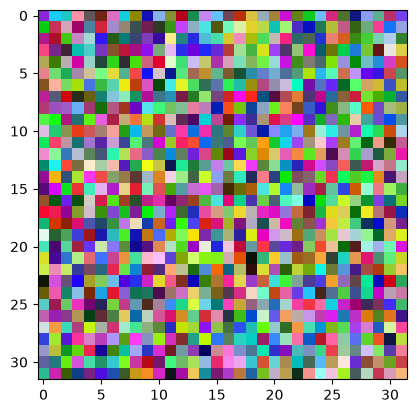

In [73]:
import numpy as np 
seed = 42
rng = np.random.default_rng(seed)
print(rng)


arr = rng.integers(0, 256, (32, 32, 3), dtype=np.uint8)

import matplotlib.pyplot as plt

plt.imshow(arr)
plt.show()